In this notebook I want to compute weighted phase lag index

In [1]:
import numpy as np
import mne
import mne_connectivity
import tensorpac
from tensorpac import Pac
from tensorpac.signals import pac_signals_wavelet
from mne_connectivity import phase_slope_index, seed_target_indices, spectral_connectivity_epochs
from mne.stats import permutation_cluster_test, permutation_cluster_1samp_test
from mne.filter import next_fast_len
from mne.preprocessing.bads import _find_outliers

from glob import glob
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
from scipy.stats import zscore, linregress, ttest_ind, ttest_rel, ttest_1samp, pearsonr
import pandas as pd
from scipy.signal import hilbert, correlate, correlation_lags
import fooof
# Import plotting functions
from fooof.plts.spectra import plot_spectrum, plot_spectra
# Import the FOOOF object
from fooof import FOOOF
from fooof import FOOOFGroup
import os 
import joblib
import statsmodels.formula.api as smf
import statsmodels.api as sm
import pickle
from tqdm import tqdm
from IPython.display import clear_output
import warnings 
from ast import literal_eval


# I only want to see warnings once
warnings.filterwarnings('ignore')

from joblib import delayed, Parallel
from statsmodels.stats import multitest

In [2]:
import sys
sys.path.append('/hpc/users/qasims01/resources/LFPAnalysis')

In [3]:
from LFPAnalysis import lfp_preprocess_utils, sync_utils, analysis_utils, nlx_utils, oscillation_utils, statistics_utils


In [4]:
base_dir = '/sc/arion' # this is the root directory for most un-archived data and results
load_dir = f'{base_dir}/work/qasims01/MemoryBanditData/EMU'

# Load the demographics data to get information about who has run the task
demo_file = f'{base_dir}/projects/guLab/Salman/EMU/MemoryBanditsDatabase.xlsx'
demo_data = pd.read_excel(demo_file, engine='openpyxl')
subj_df = demo_data[(demo_data.LongVersion==1) & (demo_data.Minerva==1)]

# Let's get rid of Iowa patients for now 

# subj_df = subj_df[subj_df.Site=='UI']
subj_df = subj_df[~subj_df['MSSMCode'].isin(['MS015', 'MS024', 'MS034', 'MS038'])]


days = ['Day1', 'Day2']
subj_ids = subj_df.MSSMCode.values
subj_formats = subj_df.format.values
subj_sites = subj_df.Site.values
subj_days = subj_df.Day2.values

In [5]:
# load behavioral data
learn_df = pd.read_csv(f'{load_dir}/learn_df_RWH.csv')
combined_df = pd.read_csv(f'{load_dir}/full_df_RWH.csv')

In [6]:
# Explicitly define a list of analysis events and the baseline event. Should correspond to the dict

evs = {'gamble_start':[-1.0, 0], 
       'feedback_start': [0, 1.5],
       'baseline_start': [0, 0.75]}

baseline_ev = 'baseline_start'
analysis_evs = ['feedback_start']

day = 'Day1'

for i in analysis_evs: 
    if i not in evs.keys(): 
        raise ValueError('This analysis event is not in the dictionary')

In [7]:
# From Bahramsharif 2013
# get where phase frequencies start / finish / number
phase_frequency = 'theta'
f_pha_start, f_pha_end = 4, 8
f_pha_nb = 30
f_pha_mid = np.linspace(f_pha_start, f_pha_end, f_pha_nb)
f_pha = np.c_[f_pha_mid - f_pha_mid / 4., f_pha_mid + f_pha_mid / 4.]
# get where amplitude frequencies start / finish / number
amp_frequency = 'hfa'

f_amp_start, f_amp_end = 70, 200
f_amp_nb = 30
f_amp_mid = np.linspace(f_amp_start, f_amp_end, f_amp_nb)
f_amp = np.c_[f_amp_mid - f_amp_mid / 8., f_amp_mid + f_amp_mid / 8.]

In [8]:
save_dir_data = '/sc/arion/projects/guLab/Salman/EphysAnalyses/Connectivity/scratch/pac'


In [ ]:
base_dir = '/sc/arion'
save_dir_plots = '/sc/arion/work/qasims01/MemoryBanditData/EMU/plots'
save_dir_data = '/sc/arion/projects/guLab/Salman/EphysAnalyses/Connectivity/scratch/pac'
# 
n_perm = 250  # number of permutations
# define the Pac object (gaussian-copula PAC) 
p = Pac(idpac=(2, 2, 0), f_pha=f_pha, f_amp=f_amp, dcomplex='wavelet')

day = 'Day1'
event = 'feedback_start'
baseline_event = 'baseline_start'
    
all_dfs = [] 

for subj_id in subj_ids:

    # baseline_start_mem
    loadpath = f'{base_dir}/projects/guLab/Salman/EphysAnalyses/{subj_id}'
    save_path = f'/sc/arion/projects/guLab/Salman/EphysAnalyses/{subj_id}/neural/{day}'
    epochs_reref = mne.read_epochs(f'{save_path}/{event}-epo.fif',  preload=True) 
    
    for phase_roi in ['HPC', 'AMY', 'dlPFC', 'dmPFC']:
        for amp_roi in ['OFC']:

            elec_df = pd.read_csv(f'{base_dir}/projects/guLab/Salman/EphysAnalyses/{subj_id}/Day1_reref_elec_df')

            buf_ms = 1000
            edges = buf_ms * (epochs_reref.info['sfreq']/1000)

            # construct the seed-to-target mapping based on your rois - matters most for PSI as this is directional 
            seed_target_df = oscillation_utils.make_seed_target_df(elec_df, epochs_reref, phase_roi, amp_roi)
            seed_target_df.rename(columns={'seed':'phase', 'target':'amp'}, inplace=True)

            pwise_dfs = []
            # for cond in conditions: 
            for hemi in ['l', 'r']:
                # first determine if ipsilateral connectivity is even possible; if not, move on. 
                # note: edit this if you want to compute contralateral connectivity 
                if hemi not in seed_target_df.index.tolist():
                    continue
                else:
                    seed_to_target = seed_target_indices(
                        seed_target_df['phase'][hemi],
                        seed_target_df['amp'][hemi])
                    
                    for pair in range(len(seed_to_target[0])):
                        # ph_ch_name = elec_df.loc[seed_to_target[0][pair], 'label']
                        # amp_ch_name = elec_df.loc[seed_to_target[1][pair], 'label']
                        ph_ch_name = epochs_reref.ch_names[seed_to_target[0][pair]]
                        amp_ch_name = epochs_reref.ch_names[seed_to_target[1][pair]]

                        amp_sig = np.squeeze(epochs_reref.copy().pick(amp_ch_name)._data) 
                        ph_sig = np.squeeze(epochs_reref.copy().pick(ph_ch_name)._data) 
                        
                        # print(amp_ch_name) 
                        
                        # if os.path.isfile(f'{save_dir_data}/{subj_id}_{phase_roi}-{amp_roi}_{ph_ch_name}-{amp_ch_name}_pac.npy'):
                        #     print('already ran this one')
                        #     continue

                        epoch_pac = p.filterfit(epochs_reref.info['sfreq'], 
                                         ph_sig, amp_sig,
                                         n_perm=n_perm, n_jobs=-1,
                                         edges=edges, random_state=0)

                        surr_mean = p.surrogates.mean(axis=0)
                        surr_std = p.surrogates.std(axis=0)
                        z_scored_pac = (epoch_pac-surr_mean)/surr_std

                        # Save out the z_scored pac so I can do individual analysis on it
                        np.save(f'{save_dir_data}/{subj_id}_{phase_roi}-{amp_roi}_{ph_ch_name}-{amp_ch_name}_pac', z_scored_pac)

                        # average the z-scores across phae and frequency amplitudes 
                        avg_conn = z_scored_pac.mean(axis=(0, 1))

                        # alternative: nan out non-significant pac_values, then sum
                        z_scored_pac[np.abs(z_scored_pac)<=1.96] = np.nan

                        sum_conn = np.nansum(z_scored_pac, axis=(0, 1))

                        pwise_df = pd.DataFrame(columns=['participant', 'roi', 'label', 'event', 'avg_conn'
                                                        'summ_conn'])

                        pwise_df['avg_conn'] = avg_conn
                        pwise_df['sum_conn'] = sum_conn
                        pwise_df['participant'] = subj_id
                        pwise_df['age'] = subj_df[subj_df.MSSMCode==subj_id].Age.values[0]
                        pwise_df['sex'] = subj_df[subj_df.MSSMCode==subj_id].Sex.str.strip().values[0]

                        pwise_df['amp_roi'] = amp_roi
                        pwise_df['phase_roi'] = phase_roi
                        pwise_df['event'] = event
                        pwise_df['band0'] = phase_frequency
                        pwise_df['band1'] = amp_frequency
                        pwise_df['trials'] = np.arange(1, len(sum_conn)+1)
                        pwise_df['label'] = f'{ph_ch_name}:{amp_ch_name}'
                        pwise_df['hemi'] = hemi


                        pwise_df = pwise_df.merge(learn_df[learn_df.participant==subj_id], on=['participant', 'trials'])

                        pwise_df['zrpe'] = (pwise_df.rpe - np.nanmean(pwise_df.rpe)) / (2*np.nanstd(pwise_df.rpe))
                        pwise_df['zpm'] = (pwise_df.DPRIME - np.nanmean(pwise_df.DPRIME)) / (2*np.nanstd(pwise_df.DPRIME))

            #             # aggregate
                        pwise_dfs.append(pwise_df)

            if len(pwise_dfs) > 0:
                all_df_pt = pd.concat(pwise_dfs)
                # to make sure I don't have to re-run subjects if i finish some:
                all_df_pt.to_csv(f'{save_dir_data}/{subj_id}_{phase_roi}-{amp_roi}_pac_{event}.csv', index=False)
                all_dfs.append(all_df_pt)

Phase Amplitude Coupling object defined


Reading /sc/arion/projects/guLab/Salman/EphysAnalyses/MS012/neural/Day1/feedback_start-epo.fif ...
    Found the data of interest:
        t =   -1000.00 ...    2500.00 ms
        0 CTF compensation matrices available
Adding metadata with 60 columns
80 matching events found
No baseline correction applied
0 projection items activated


    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrogates (Swap amplitude time blocks (Bahramisharif et al. 2013), 250 permutations, random_state=0)
    infer p-values at (p=0.05, mcp=maxstat)
    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrogates (Swap amplitude time blocks (Bahramisharif et al. 2013), 250 permutations, random_state=0)
    infer p-values at (p=0.05, mcp=maxstat)
    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrogates (Swap amplitude time blocks (Bahramisharif et al. 2013), 250 permutations, random_state=0)
    infer p-values at (p=0.05, mcp=maxstat)
    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrog

Reading /sc/arion/projects/guLab/Salman/EphysAnalyses/UI001/neural/Day1/feedback_start-epo.fif ...
    Found the data of interest:
        t =   -1000.00 ...    2500.00 ms
        0 CTF compensation matrices available
Adding metadata with 48 columns
80 matching events found
No baseline correction applied
0 projection items activated
Reading /sc/arion/projects/guLab/Salman/EphysAnalyses/MS016/neural/Day1/feedback_start-epo.fif ...
    Found the data of interest:
        t =   -1000.00 ...    2500.00 ms
        0 CTF compensation matrices available
Adding metadata with 65 columns
80 matching events found
No baseline correction applied
0 projection items activated


    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrogates (Swap amplitude time blocks (Bahramisharif et al. 2013), 250 permutations, random_state=0)
    infer p-values at (p=0.05, mcp=maxstat)
    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrogates (Swap amplitude time blocks (Bahramisharif et al. 2013), 250 permutations, random_state=0)
    infer p-values at (p=0.05, mcp=maxstat)
    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrogates (Swap amplitude time blocks (Bahramisharif et al. 2013), 250 permutations, random_state=0)
    infer p-values at (p=0.05, mcp=maxstat)
    extract phases (n_pha=30) and amplitudes (n_amps=30)
    true PAC estimation using Modulation Index (MI, Tort et al. 2010)
    compute surrog

In [21]:
f'{ph_ch_name}:{amp_ch_name}'

'rhplt1-rhplt2:rmolf1-rmolf2'

WARNING | 3d pac array has been given as an input. Only 2d arrays are supported for plotting. Taking the mean across the last dimension


<Axes: title={'center': 'Gaussian Copula PAC (gcPac)'}, xlabel='Frequency for phase (hz)', ylabel='Frequency for amplitude (hz)'>

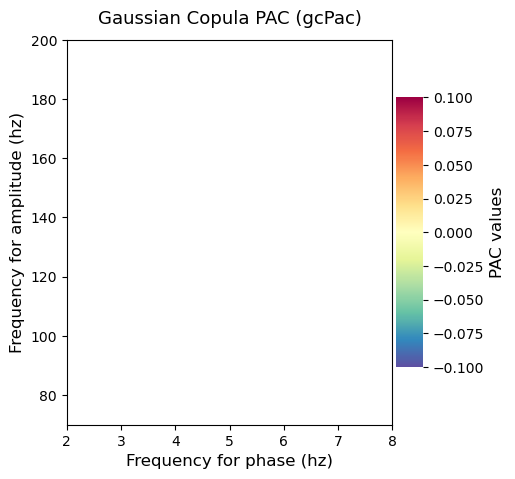

In [20]:
p.f = plt.figure(figsize=(11, 5))
plt.subplot(121)
p.comodulogram(z_scored_pac, title=str(p), cmap='Spectral_r')


In [12]:
z_scored_pac

array([[[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [ 2.8567355 ,         nan,         nan, ...,         nan,
          2.34865623,         nan],
        [ 2.45966107,         nan,         nan, ...,         nan,
          2.02954003,         nan],
        [ 2.60040617,         nan,         nan, ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,         nan,
                 nan,  2.361327  ],
        [        nan,         nan,         nan, ..., -2.09123736,
                 nan,  2.30802221],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [        nan,         nan,         nan, ...,  

In [50]:
# f = plt.figure(figsize=(11, 5))
# plt.subplot(121)
# p.comodulogram(z_scored_pac, title=str(p), cmap='Spectral_r')


# t_obs, clusters, cluster_p_values, h0 = permutation_cluster_1samp_test(np.moveaxis(z_scored_pac, -1, 0), 
#                                                                        n_permutations=1000, n_jobs=-1, tail=1)
# # # split two conditions:
# # p.comodulogram(z_scored_pac[:, :, pwise_df.rpe<0], title=str(p), cmap='Spectral_r')
# # plt.subplot(122)
# # p.comodulogram(z_scored_pac[:, :, pwise_df.rpe>0], title=str(p), cmap='Spectral_r')
# # t_obs, clusters, cluster_p_values, h0 = permutation_cluster_test([np.moveaxis(z_scored_pac[:, :, pwise_df.rpe>0], -1, 0),
# #                                                                   np.moveaxis(z_scored_pac[:, :, pwise_df.rpe<0], -1, 0)],
# #                                                                        n_permutations=500, n_jobs=-1, tail=1)
# # # if len(cluster_p_values) > 0:
# #     if any(cluster_p_values <= 0.05):
# #         f = plt.figure(figsize=(11, 5))
# #         plt.subplot(121)
# #         p.comodulogram(z_scored_pac, title=str(p), cmap='Spectral_r')


# #         # create new stats image with only significant clusters
# #         t_obs_plot = np.nan * np.ones_like(t_obs)
# #         t_obs_background = t_obs.copy()
# #         for c, p_val in zip(clusters, cluster_p_values):
# #             if p_val <= 0.05:
# #                 t_obs_plot[c] = t_obs[c]
# #                 t_obs_background[c] = np.nan